In [23]:
#Standard libraries
import sunpy
import sunpy.map
import numpy as np
from math import *
import astropy.units as u
from astropy.io import fits
import os
from pathlib import Path
import pandas as pd
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import re
import glob

#Extra functions/modules from libraries
from astropy.coordinates import SkyCoord
from sunpy.coordinates import frames
from astropy.time import Time
from astropy.coordinates import get_sun
from astropy.constants import R_sun
from sunpy.coordinates import sun
from scipy.ndimage import map_coordinates, gaussian_filter1d
from scipy.ndimage import label




In [2]:
CHASE_files = "C:/Users/joeyc/OneDrive/Documents/Uni Stuff/SunbYte/CHASE Data/Comparing Data/01_10_2025"
GONG_files = "C:/Users/joeyc/OneDrive/Documents/Uni Stuff/SunbYte/Introductory Task/GONG Images"

Found 195 GONG images.
957.25805135874
GONG 1: 13.652 arcsec
957.2695833446413
GONG 2: 13.223 arcsec
957.281117429451
GONG 3: 13.115 arcsec
957.292589496948
GONG 4: 14.095 arcsec
957.3041277059858
GONG 5: 14.526 arcsec
957.3158603062842
GONG 6: 13.762 arcsec
957.3272743425163
GONG 7: 11.669 arcsec
957.3388186099165
GONG 8: 12.127 arcsec
957.3503648510342
GONG 9: 12.215 arcsec
957.3619130447895
GONG 10: 12.879 arcsec
957.3735273427741
GONG 11: 12.371 arcsec
957.3849510224251
GONG 12: 14.094 arcsec
957.3966333239881
GONG 13: 13.069 arcsec
957.4081249226778
GONG 14: 11.381 arcsec
957.419682561454
GONG 15: 10.800 arcsec
957.431242025179
GONG 16: 13.269 arcsec
957.4428675266226
GONG 17: 12.689 arcsec
957.4545590739174
GONG 18: 12.799 arcsec
957.4661881664481
GONG 19: 13.671 arcsec
957.4776904892936
GONG 20: 12.650 arcsec
957.4892587826615
GONG 21: 12.566 arcsec
957.5008287707866
GONG 22: 11.960 arcsec
957.5124004318245
GONG 23: 13.332 arcsec
957.5239737438685
GONG 24: 13.410 arcsec
957.5355

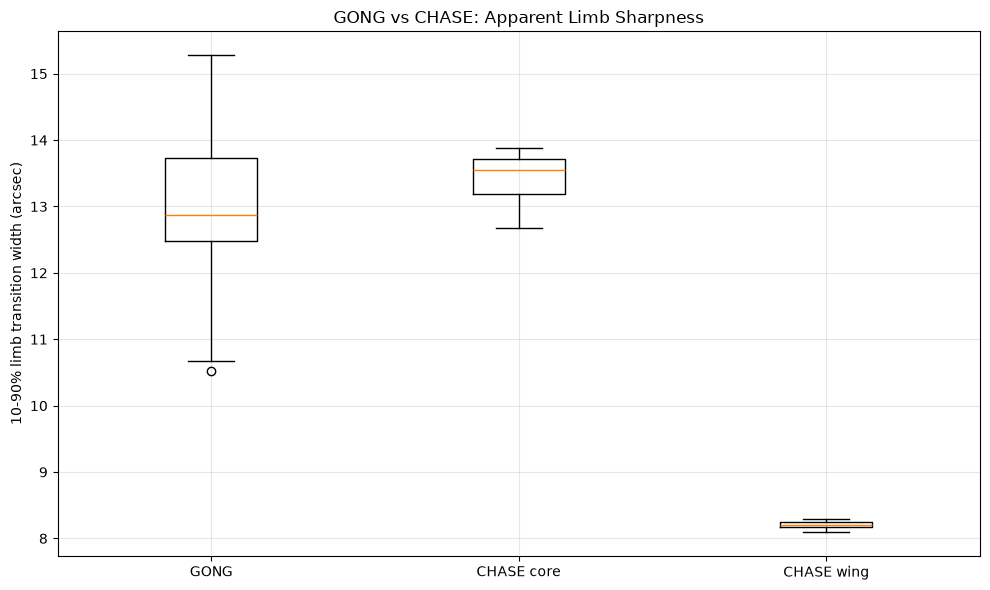

In [ ]:
# ============================================================
# 1. SETTINGS
# ============================================================

GONG_DIR = Path(GONG_files)
CHASE_DIR = Path(CHASE_files)

OUTPUT_DIR = Path("C:/Users/joeyc/OneDrive/Documents/Uni Stuff/SunbYte/CHASE Data/Comparing Data")
OUTPUT_DIR.mkdir(exist_ok=True)

#GONG image/index closest to CHASE images
GONG_IMAGE_NUMBER = 67

# GONG images are remapped to a nominal solar radius of 900 pixels by the GONG processing pipeline
GONG_RADIUS_PIXELS = 900

# Set to None to estimate geometry automatically.
# Otherwise use (x centre, y centre, radius).
GONG_GEOMETRY = None
CHASE_GEOMETRY = None

N_ANGLES = 180 #Number of angular positions around the solar limb at which to measure the width

PROFILE_WIDTH = 15 #Distance from the limb over which to analyse the profile.

SMOOTHING = 1.0 #Smooth the radial intensity profiles slightly.

# ============================================================
# 2. LOAD IMAGES
# ============================================================

def load_jp2(filepath):
    """Load a GONG JPEG2000 image."""
    
    image = mpimg.imread(filepath)
    return image.astype(float)


def load_fits(filepath):
    """Load CHASE FITS data and its header."""

    rsm = fits.open(filepath)
    data = rsm[1].data.copy()
    header = rsm[1].header.copy()
    return data, header

def get_GONG_time(filepath):
    match = re.search(r"(\d{4})-?(\d{2})-?(\d{2}) (\d{2})_?(\d{2})_?(\d{2})", filepath)

    if match is None:
        raise ValueError(f"No date/time found in {filepath!r}")
    
    year, month, day, hour, minute, second = match.groups()
    observation_time = f"{year}-{month}-{day}T{hour}:{minute}:{second}"
    return observation_time

    
# ============================================================
# 3. SOLAR DISC GEOMETRY
# ============================================================
def get_CHASE_geometry(image, header):
    """
    Calculate solar disc geometry using CHASE FITS metadata
    and SunPy WCS.

    Returns:
        cx: Solar disc centre x-coordinate (pixels)
        cy: Solar disc centre y-coordinate (pixels)
        radius: Solar angular radius converted to pixels
    """

    observation_time = header["DATE_OBS"]

    # Define solar disc centre in helioprojective coordinates
    coord_HIS = SkyCoord(0 * u.arcsec, 0 * u.arcsec, obstime=observation_time, observer="earth", frame=frames.Helioprojective)

    # Reconstruct the CHASE WCS
    header_wcs = sunpy.map.make_fitswcs_header(image, coord_HIS,
                                        reference_pixel=[header["CRPIX1"], header["CRPIX2"]] * u.pixel,
                                        scale=[0.5218 * header["BIN"], 0.5218 * header["BIN"]] * u.arcsec / u.pixel,
                                        telescope="CHASE",
                                        instrument="RSM")

    # Create SunPy map
    solar_map = sunpy.map.Map(image, header_wcs)

    # Get solar disc centre in pixel coordinates
    cx = header["CRPIX1"]
    cy = header["CRPIX2"]

    # Calculate apparent angular radius of the Sun
    angular_radius = sun.angular_radius(solar_map.date)

    # Convert angular radius into pixels
    radius = (angular_radius / solar_map.scale.axis1).to_value(u.pixel)

    return cx, cy, radius

def get_GONG_geometry(image): #Calculate GONG solar disc geometry, H-alpha images remapped to standard disc with radius of 860 pixels

    height, width = image.shape

    # Centre of the image (zero-based pixel coordinates)
    cx = (width - 1) / 2
    cy = (height - 1) / 2

    radius = GONG_RADIUS_PIXELS #GONG solar radius is 900 pixels

    return cx, cy, radius


# ============================================================
# 4. CALCULATE SOLAR ANGULAR RADIUS
# ============================================================

def solar_angular_radius(observation_time):
    """
    Calculate the apparent angular radius of the Sun on the observation date.
    """

    time = Time(observation_time)
    sun = get_sun(time) #Astropy function that determines the location of the Sun at a given time
    distance = sun.distance

    angular_radius = np.arcsin((R_sun / distance).decompose().value) * u.rad #Trigonometry to fins the angular radius of the Sun in radians
    print(angular_radius.to(u.arcsec).value)

    return angular_radius.to(u.arcsec).value #Returns angular radius in arcseconds, for CHASE images this can be found in the header [RSUN_OBS]


# ============================================================
# 5. CALCULATE PIXEL SCALE
# ============================================================

def calculate_pixel_scale(radius_pixels, observation_time): #radius_pixels = angular radius of 1 pixel
    """
    Convert pixels to arcseconds using the apparent angular solar radius.
    """
    angular_radius = solar_angular_radius(observation_time)
    return angular_radius / radius_pixels

# ============================================================
# 6. CALCULATE LIMB EDGE WIDTH
# ============================================================

def find_crossing(profile, radii, level):
    """
    Find the radial position at which the normalised
    intensity crosses a specified level (e.g. 90% and 10%).
    """

    indices = np.where(profile <= level)[0]

    if len(indices) == 0:
        return np.nan

    i = indices[0]

    if i == 0:
        return np.nan

    x1, x2 = radii[i - 1], radii[i]
    y1, y2 = profile[i - 1], profile[i]

    if y2 == y1:
        return np.nan

    return x1 + (level - y1) * (x2 - x1) / (y2 - y1)


def calculate_limb_width(image, cx, cy, radius):
    """
    Calculate the 10-90% edge transition width
    at multiple positions around the solar limb.

    Returns:
        widths_pixels
        mean radial profile
        radial offsets
    """

    h, w = image.shape
    radial_offsets = np.linspace(-PROFILE_WIDTH, PROFILE_WIDTH, 101)
    angles = np.linspace(0, 2 * np.pi, N_ANGLES, endpoint=False)

    widths = []
    all_profiles = []

    for angle in angles:

        # Coordinates along a radial line
        r = radius + radial_offsets

        x = cx + r * np.cos(angle)
        y = cy + r * np.sin(angle)

        # Ensure coordinates are inside image
        if (np.any(x < 1) or np.any(x >= w - 1) or np.any(y < 1) or np.any(y >= h - 1)):
            continue

        profile = map_coordinates(image, [y, x], order=1, mode="nearest")

        profile = gaussian_filter1d(profile, sigma=SMOOTHING)

        # Estimate inside and outside intensity
        inside = np.median(profile[5:20])
        outside = np.median(profile[-20:-5])

        contrast = inside - outside

        if abs(contrast) < 1e-10:
            continue

        # Normalise: inside approximately 1,
        # outside approximately 0.
        normalised = (profile - outside) / contrast

        # Reject profiles with a strongly abnormal transition
        if not np.all(np.isfinite(normalised)):
            continue

        if normalised[5] < 0.5 or normalised[-5] > 0.5:
            continue

        # Find 90% and 10% crossings
        r90 = find_crossing(normalised, radial_offsets, 0.9)
        r10 = find_crossing(normalised, radial_offsets, 0.1)

        if np.isfinite(r90) and np.isfinite(r10):

            width = r10 - r90

            if 0 < width < 2 * PROFILE_WIDTH:
                widths.append(width)
                all_profiles.append(normalised)

    if len(widths) == 0:
        raise ValueError("No valid limb profiles found. Check disc geometry and PROFILE_WIDTH.")

    mean_profile = np.mean(all_profiles, axis=0)

    return np.array(widths), mean_profile, radial_offsets


# ============================================================
# 7. ANALYSE ONE IMAGE
# ============================================================

def analyse_image(image, instrument, filename, observation_time, geometry=None, wavelength="N/A"):

    if geometry is None:
        raise ValueError("No valid geometry found")
    else:
        cx, cy, radius = geometry

    widths, mean_profile, offsets = calculate_limb_width(image, cx, cy, radius)

    pixel_scale = calculate_pixel_scale(radius, observation_time)

    # Median is less sensitive to unusual limb features
    median_width = np.median(widths)

    resolution_arcsec = median_width * pixel_scale

    result = {
        "instrument": instrument,
        "filename": filename,
        "time": observation_time,
        "wavelength": wavelength,
        "centre_x": cx,
        "centre_y": cy,
        "radius_pixels": radius,
        "pixel_scale_arcsec_pixel": pixel_scale,
        "limb_width_pixels": median_width,
        "limb_width_arcsec": resolution_arcsec,
        "mean_width_pixels": np.mean(widths),
        "std_width_pixels": np.std(widths),
        "valid_profiles": len(widths)
    }

    return result, widths, mean_profile, offsets


# ============================================================
# 8. PROCESS GONG IMAGES
# ============================================================

results = []
gong_files = sorted(glob.glob(os.path.join(GONG_DIR, "*.jp2")))

print(f"Found {len(gong_files)} GONG images.")

for index, filepath in enumerate(gong_files):
    try:
        image = load_jp2(filepath)
        observation_time = get_GONG_time(filepath)

        geometry = get_GONG_geometry(image)

        result, widths, profile, offsets = analyse_image(image=image, 
                                                         instrument="GONG", 
                                                         filename=filepath, 
                                                         observation_time=observation_time, 
                                                         geometry=geometry)

        results.append(result)

        print(f"GONG {index + 1}: {result['limb_width_arcsec']:.3f} arcsec")

    except Exception as error:
        print(f"Error processing {filepath}: {error}")


# ============================================================
# 9. PROCESS CHASE IMAGES
# ============================================================

chase_files = sorted(glob.glob(os.path.join(CHASE_DIR, "*.fits")))

print(f"Found {len(chase_files)} CHASE FITS files.")

for filepath in chase_files:
    try:
        data, header = load_fits(filepath)

        print(filepath, data.shape)

        observation_time = header["DATE_OBS"] #Extract observation time from FITS header

        if data.ndim != 3: #Account for files with a 2D rather than 3D array
            raise ValueError("Expected a 3D FITS data cube.")

        wavelengths = {
            "core": 68,
            "wing": -10
        }

        for label_name, slice_index in wavelengths.items():
            image = data[slice_index, :, :]

            # Calculate geometry individually for each CHASE image
            geometry = get_CHASE_geometry(image, header)

            result, widths, profile, offsets = analyse_image(image=image, 
                                                             instrument="CHASE", 
                                                             filename=filepath, 
                                                             observation_time=observation_time, 
                                                             geometry=geometry, 
                                                             wavelength=label_name)
            
            results.append(result)

            print(f"CHASE {filepath} {label_name}: {result['limb_width_arcsec']:.3f} arcsec")

    except Exception as error:

        print(f"Error processing {filepath}: {error}")


# ============================================================
# 10. SAVE RESULTS
# ============================================================

df = pd.DataFrame(results)

df.to_csv(os.path.join(OUTPUT_DIR, "spatial_resolution_results.csv"), index=False)

print("\nAnalysis complete.")

print(df.groupby(["instrument", "wavelength"])["limb_width_arcsec"].describe())


# ============================================================
# 11. PLOT COMPARISON
# ============================================================

plt.figure(figsize=(10, 6))

gong = df[df["instrument"] == "GONG"]
chase_core = df[(df["instrument"] == "CHASE") & (df["wavelength"] == "core")]
chase_wing = df[(df["instrument"] == "CHASE") & (df["wavelength"] == "wing")]

plt.boxplot([
        gong["limb_width_arcsec"].dropna(),
        chase_core["limb_width_arcsec"].dropna(),
        chase_wing["limb_width_arcsec"].dropna()
            ],
        tick_labels=["GONG", "CHASE core", "CHASE wing"])

plt.ylabel("10-90% limb transition width (arcsec)")
plt.title("GONG vs CHASE: Apparent Limb Sharpness")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(os.path.join(OUTPUT_DIR, "resolution_comparison.png"), dpi=300)

plt.show()


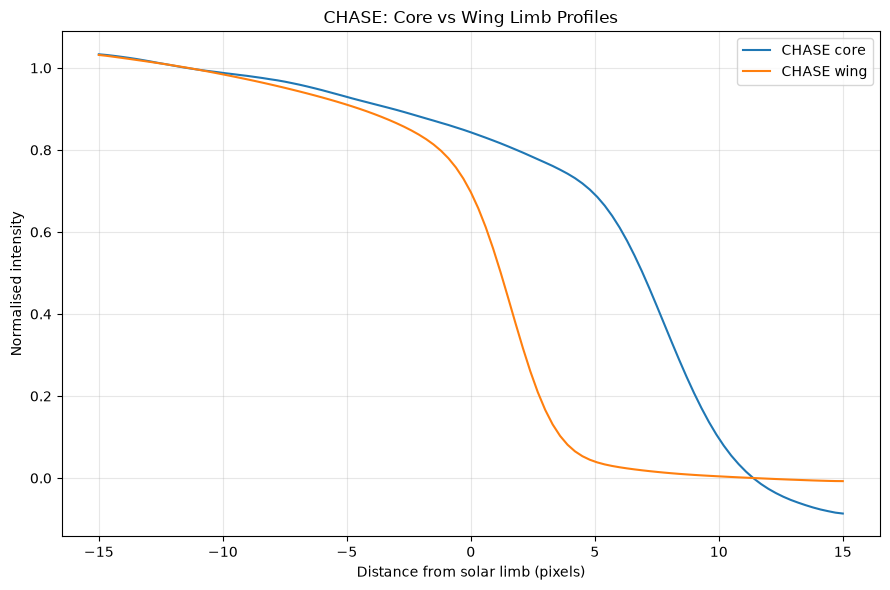

In [46]:

plt.figure(figsize=(9, 6))

for wavelength in ["core", "wing"]:
    profiles = []

    for filepath in chase_files:
        data, header = load_fits(filepath)

        if wavelength == "core":
            image = data[68, :, :]
        else:
            image = data[-10, :, :]

        geometry = get_CHASE_geometry(image, header)

        _, _, profile, offsets = analyse_image(
            image=image,
            instrument="CHASE",
            filename=filepath,
            observation_time=header["DATE_OBS"],
            geometry=geometry,
            wavelength=wavelength
        )

        profiles.append(profile)

    mean_profile = np.mean(profiles, axis=0)

    plt.plot(
        offsets,
        mean_profile,
        label=f"CHASE {wavelength}"
    )

plt.xlabel("Distance from solar limb (pixels)")
plt.ylabel("Normalised intensity")
plt.title("CHASE: Core vs Wing Limb Profiles")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

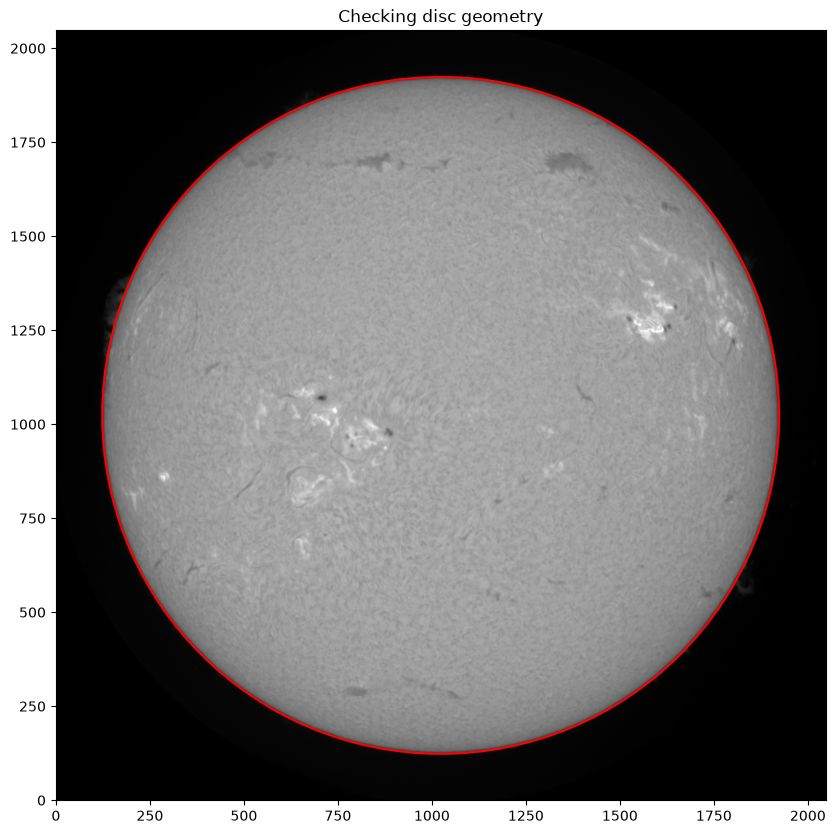

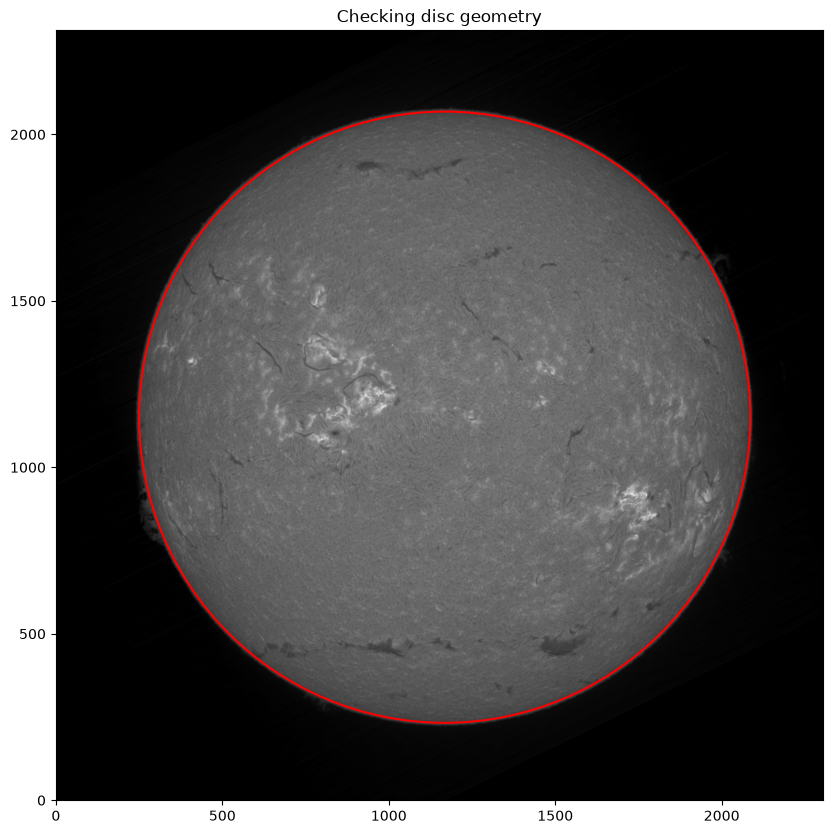

In [31]:
def check_geometry(image, geometry):
    cx, cy, radius = geometry
    fig, ax = plt.subplots(figsize=(10, 10))

    ax.imshow(image, cmap="grey", origin="lower")

    circle = plt.Circle((cx, cy), radius, fill=False, color="red", linewidth=1.5)

    ax.add_patch(circle)

    ax.set_title("Checking disc geometry")
    plt.show()

#Checking GONG files
data= load_jp2(gong_files[67]) #Index 67 is closest to the time of CHASE images
image = data
geometry = get_GONG_geometry(image)

check_geometry(image, geometry)

#Checking geometry of CHASE files
data, header = load_fits(chase_files[0])
image = data[68, :, :]
geometry = get_CHASE_geometry(image, header)

check_geometry(image, geometry)

In [ ]:
def open_files(filepath, image_resolution=2048): #Takes inputs filepath and image_resolution - if no value is provided for the latter it defaults to 2048 pixels square
  original_files = sorted(glob.glob(os.path.join(filepath, "*.jp2"))) #Finding all files in the filepath that are .jp2 files
  num_images = len(original_files) #Counting the number of files in 'original_files'
  print(f"Number of images = {num_images}") #Checking the correct amount of images have been loaded in

  image_files = np.empty((num_images, image_resolution, image_resolution)) #Creating an empty array with length 'num_images', where each element has dimensions (image_resolution x image_resolution)
  
  for i, image in enumerate(original_files): #Iterate over each image
    current_image = mpimg.imread(image) #Creates an image from the array
    image_files[i] = current_image #Adds the current image to its respective location in image_files
  
  return image_files

loaded_images = open_files(GONG_files) #Using the function for the GONG images in "GONG_files"

In [9]:
def core_wing_plot(file_directory, filename):
    current_file = os.path.join(file_directory, filename)
    rsm = fits.open(current_file)

    #rsm.info()
    #print(print(repr(rsm[1].header)))


    hacore = rsm[1].data[68, :, :] #~Core wavelength 6562.87 A
    hawing = rsm[1].data[-10, :, :] #Wing wavelength 6564.6

    coord_HIS = SkyCoord(0 * u.arcsec, 0 * u.arcsec, obstime = rsm[1].header["DATE_OBS"], observer = 'earth', \
                     frame = frames.Helioprojective)
    headerwing = sunpy.map.make_fitswcs_header(hawing, coord_HIS,
                                       reference_pixel = \
                                       [rsm[1].header['CRPIX1'], rsm[1].header['CRPIX2']] * u.pixel,
                                       scale = [0.5218 * 2, 0.5218 * 2] * u.arcsec / u.pixel,
                                       telescope = 'CHASE', instrument = 'RSM')
    headercore = sunpy.map.make_fitswcs_header(hacore, coord_HIS,
                                       reference_pixel = \
                                       [rsm[1].header['CRPIX1'], rsm[1].header['CRPIX2']] * u.pixel,
                                       scale = [0.5218 * 2, 0.5218 * 2] * u.arcsec / u.pixel,
                                       telescope = 'CHASE', instrument = 'RSM')

    hawing_map = sunpy.map.Map(hawing, headerwing)
    hacore_map = sunpy.map.Map(hacore, headercore)
    fig = plt.figure(figsize=(20, 10))

    #This function vvv can be used to find the time and date of the image, but takes many more lines than rsm[1].header(["DATA_OBS"])
    #def find_date_time(file_name): #Don't need this if using .header["DATE_OBS"], but took about 40 mins to understand how to use re :(
    #m = re.search(r"RSM(\d{4})(\d{2})(\d{2})T(\d{2})(\d{2})(\d{2})", file_name)
    #if m is None:
    #    raise ValueError(f"No date/time found in {file_name!r}")
    #year, month, day, hour, minute, second = m.groups()
    #return f"{year}-{month}-{day} {hour}:{minute}:{second}"

    ax0 = fig.add_subplot(1, 2, 1, projection=hacore_map)
    hacore_map.plot(axes=ax0, cmap='afmhot', vmin=0, vmax=4 * hacore.mean())
    #hacore_map.draw_grid(color = 'white') #Plots a grid over the Sun
    #hacore_map.draw_limb() #Plots a bold circle around the limb of the Sun

    ax1 = fig.add_subplot(1, 2, 2, projection=hawing_map)
    hawing_map.plot(axes=ax1, cmap='afmhot', vmin=0, vmax=4 * hawing.mean())

    plt.show()
    return hacore_map

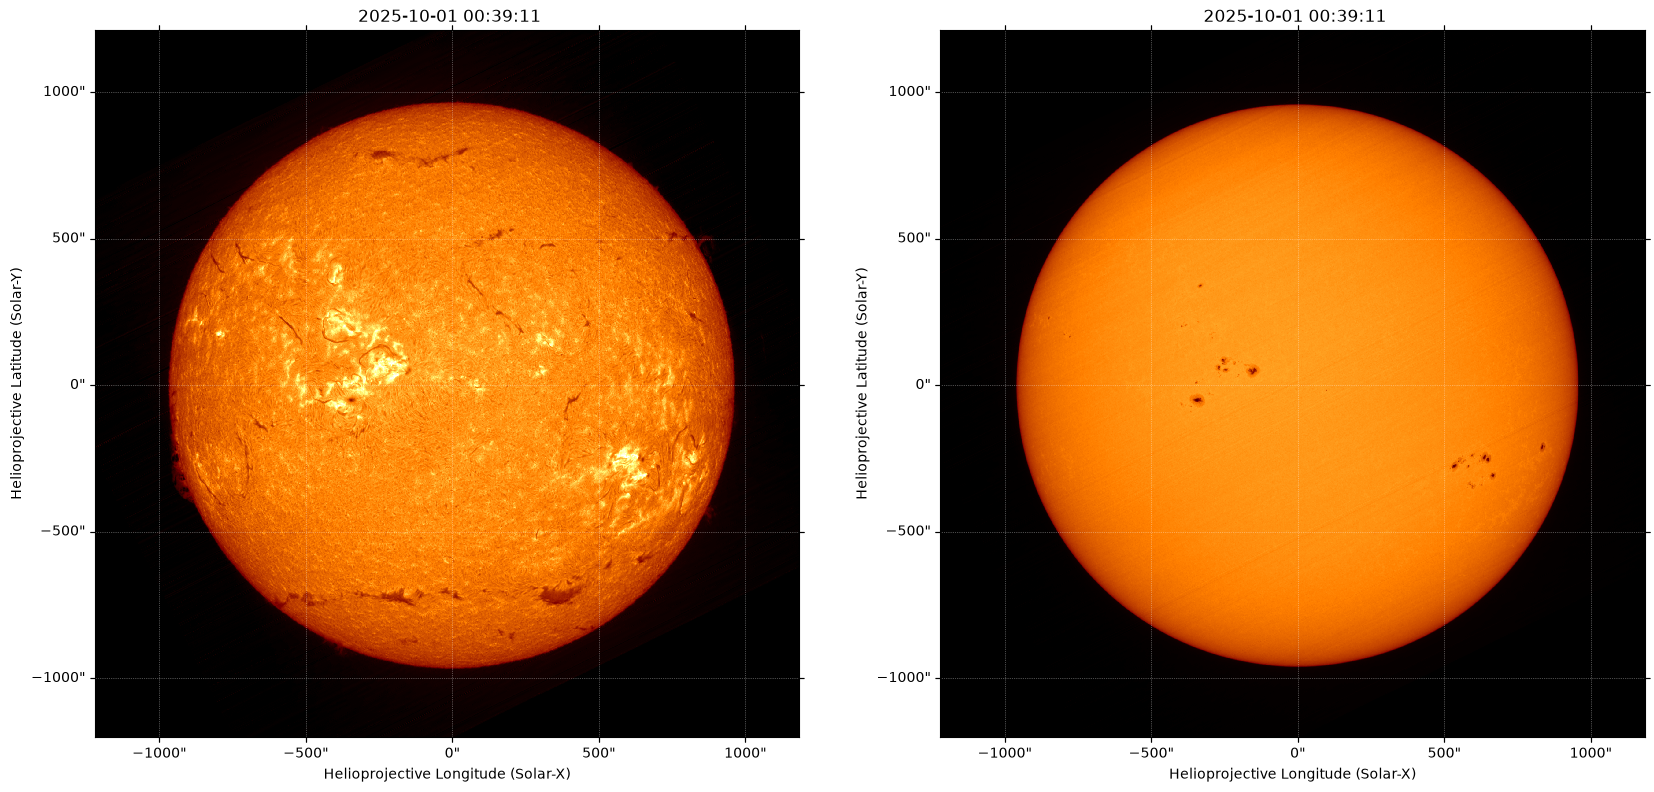

Observatory,CHASE
Instrument,RSM
Detector,
Measurement,Unknown
Wavelength,Unknown
Observation Date,2025-10-01 00:39:11
Exposure Time,Unknown
Dimension,[2304. 2313.] pix
Coordinate System,helioprojective
Scale,[1.0436 1.0436] arcsec / pix
Reference Pixel,[1168.16298212 1150.55677358] pix

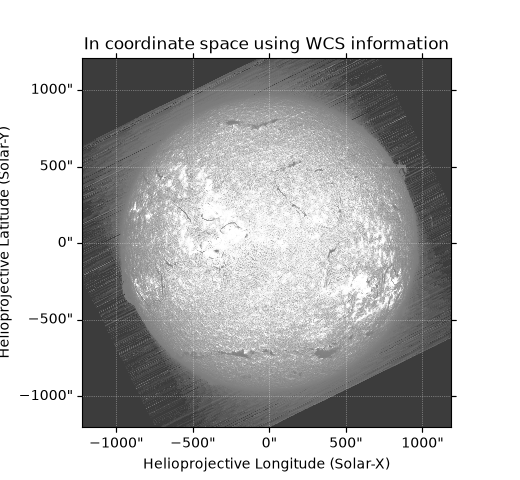
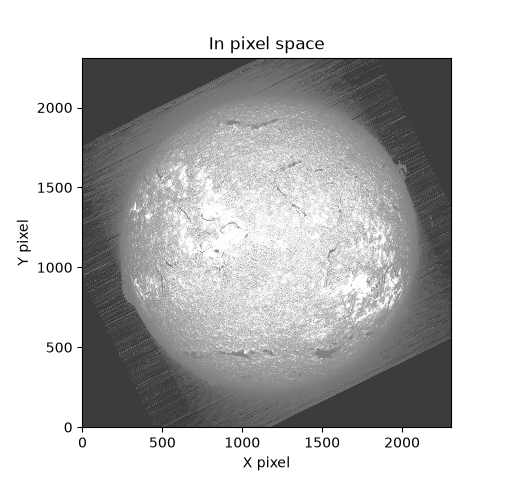
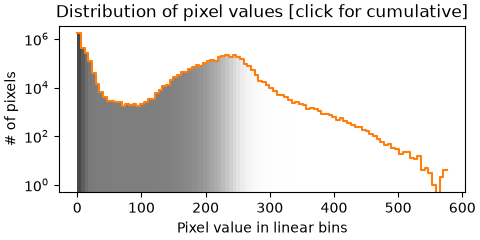
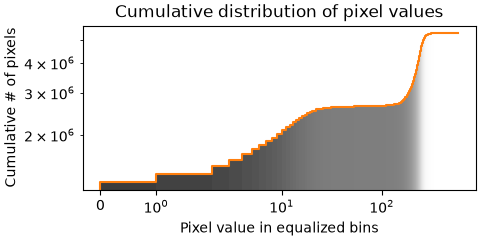

In [10]:
core_wing_plot(CHASE_files, "RSM20251001T003911_0000_HA.fits")